# Evaluation for Grammar

In [9]:
import argparse
import json
import time
from dataclasses import replace
from difflib import SequenceMatcher
from pathlib import Path

import mlflow
from langchain_core.output_parsers import StrOutputParser

from src.llm.factory import get_model            # adjust if your import path differs
from src.config import get_config
from src.tasks import get_task

# Override path for notebook
import sys
sys.path.insert(0, "C:/Users/Silas/Documents/03_Programming/02_Python/01_Studium/localQuill-v2")

In [2]:
CFG_FIELDS = {"model", "temperature", "max_tokens", "collection", "top_k"}

In [3]:
def build_task(style: str, overrides: dict):
    """Real GrammarTask, with config and model swapped for this eval run."""
    cfg = replace(get_config("grammar", style),
                  **{k: v for k, v in overrides.items() if k in CFG_FIELDS})
    task = get_task("grammar", style)
    task.config = cfg
    task.model = get_model("grammar", style, cfg=cfg, provider=overrides.get("provider"))
    task.chain = task.model | StrOutputParser()
    return task, cfg

In [4]:
def run_case(task, text: str, expected: str | None) -> dict:
    prompt = task.build_prompt(text)
    start = time.time()
    try:
        response, error = task.chain.invoke(prompt), None
    except Exception as e:                    # keep the loop alive on one failure
        response, error = "", f"{type(e).__name__}: {e}"
    latency = time.time() - start
    return {
        "input": text,
        "expected": expected,
        "prompt": prompt,
        "response": response,
        "error": error,
        "latency_s": round(latency, 3),
        "prompt_chars": len(prompt),
        "response_chars": len(response),
        "similarity": (SequenceMatcher(None, response.strip(), expected.strip()).ratio()
                       if expected and not error else None),
    }

In [14]:
def evaluate(config_path: Path, cases: list[dict], style: str) -> None:
    overrides = json.loads(config_path.read_text(encoding="utf-8"))
    run_name = overrides.get("name", config_path.stem)
    task, cfg = build_task(style, overrides)

    with mlflow.start_run(run_name=run_name):
        mlflow.log_params({
            "provider": overrides.get("provider", "env default"),
            "model": cfg.model, "temperature": cfg.temperature,
            "max_tokens": cfg.max_tokens, "style": style,
            "collection": cfg.collection, "top_k": cfg.top_k,
            "n_cases": len(cases), "config_file": config_path.name,
        })
        mlflow.log_text(type(task).template or "", "prompt_template.txt")

        rows = []
        for i, case in enumerate(cases):
            row = run_case(task, case["input"], case.get("expected"))
            rows.append(row)
            mlflow.log_metric("latency_s", row["latency_s"], step=i)
            if row["similarity"] is not None:
                mlflow.log_metric("similarity", row["similarity"], step=i)

        ok = [r for r in rows if not r["error"]]
        sims = [r["similarity"] for r in ok if r["similarity"] is not None]
        mlflow.log_metrics({
            "error_rate": 1 - len(ok) / len(rows),
            "latency_mean_s": sum(r["latency_s"] for r in ok) / max(len(ok), 1),
            "latency_max_s": max((r["latency_s"] for r in ok), default=0),
            "response_chars_mean": sum(r["response_chars"] for r in ok) / max(len(ok), 1),
            **({"similarity_mean": sum(sims) / len(sims)} if sims else {}),
        })
        # One table with model, prompt and response per case.
        mlflow.log_table(data={k: [r[k] for r in rows] for k in rows[0]},
                         artifact_file="results.json")
        first_err = next((r["error"] for r in rows if r["error"]), None)
        print(f"{run_name}: {len(ok)}/{len(rows)} ok" + (f" | first error: {first_err}" if first_err else ""))

In [24]:
from pathlib import Path
import json
import mlflow

base = Path("C:/Users/Silas/Documents/03_Programming/02_Python/01_Studium/localQuill-v2/evaluation/notebooks/eval")
data_path = base / "grammar_input.json"
config_paths = sorted((base / "configs").glob("*.json"))

cases = json.loads(data_path.read_text(encoding="utf-8"))
assert isinstance(cases, list) and "input" in cases[0], "grammar_input.json must be a list of cases"
print(f"{len(cases)} cases, {len(config_paths)} configs")

# Since we do not use the basic URL
mlflow.set_tracking_uri("http://127.0.0.1:5001")
mlflow.set_experiment("Test Grammar")

for config in config_paths:
    evaluate(config, cases, "formal")

2026/11/08 22:49:32 INFO mlflow.tracking.fluent: Experiment with name 'Test Grammar' does not exist. Creating a new experiment.


2 cases, 1 configs


[grammar] retrieval skipped: ChromaDB not found at './chroma'.
[grammar] retrieval skipped: ChromaDB not found at './chroma'.


qwen-coder-0.5b-lmstudio: 2/2 ok
🏃 View run qwen-coder-0.5b-lmstudio at: http://127.0.0.1:5001/#/experiments/1/runs/1c49708c4e9f4f418225b109a9bf9455
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1


In [25]:
print(mlflow.get_tracking_uri())

http://127.0.0.1:5001


In [17]:
# LM Studio Debugging
import src.llm.factory as f   # adjust the import path if yours differs
print(f.LMSTUDIO_URL)

import httpx
print(httpx.get("http://127.0.0.1:1234/v1/models", timeout=3).status_code)

http://127.0.0.1:1234/v1


In [27]:
# ToDo:
    # Metrics Time, Token, Tokens per Second, etc
        # (Claude) stream_usage = true in factory.py and the changes that come from that
    # Errant metric comparing response with original error prone text.
    # Errant metric comparing response with Online Corrected Text.
    # Do everything in a script, with variable input and configurations.
        # Prepare the experiments. 10 Formal, 10 Fiction. (Add errors. 2 Outline, 2 User Files, 2 Both, 4 Only Style RAGS)

## From Results

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

In [ ]:
fiction = Path("../../data/eval/results/grammar/fiction")
fiction_norag = Path("../../data/eval/results/grammar/fiction-norag")

embedding_path = fiction / "embedding_refs.csv"
summary_l_path = fiction / "summary_long.csv"
summary_l_path_norag = fiction_norag / "summary_long.csv"

In [13]:
df = pd.read_csv(summary_l_path)
df.head()

,model,setting_id,metric,mean,median,std,n_runs
0,gemma4:e4b,t0.0,cos_doc,0.985595,0.985595,NaN,1
1,gemma4:e4b,t0.0,cos_mean,0.998328,0.998328,NaN,1
2,gemma4:e4b,t0.0,cos_min,0.991983,0.991983,NaN,1
3,gemma4:e4b,t0.0,f05_best,0.413223,0.413223,NaN,1
4,gemma4:e4b,t0.0,gen_tok_per_s,76.647240,76.647240,NaN,1


In [24]:
df_metric = df.groupby(["model", "setting_id", "metric"]).mean()
df_metric.head(13)

mean     median  std  n_runs
model      setting_id metric                                                
gemma4:e4b t0.0       cos_doc               0.985595   0.985595  NaN     1.0
                      cos_mean              0.998328   0.998328  NaN     1.0
                      cos_min               0.991983   0.991983  NaN     1.0
                      f05_best              0.413223   0.413223  NaN     1.0
                      gen_tok_per_s        76.647240  76.647240  NaN     1.0
                      judge_correction      4.942496   4.942496  NaN     1.0
                      judge_preservation    4.318980   4.318980  NaN     1.0
                      overcorr_per_100tok   1.766980   1.766980  NaN     1.0
                      precision_best        0.380952   0.380952  NaN     1.0
                      tp_rate               0.410000   0.410000  NaN     1.0
                      tp_rate_consensus     0.736842   0.736842  NaN     1.0
                      wall_s               21.806163  21.806163  NaN     1.0
                      wall_s_median        25.507587  25.507587  NaN     1.0

In [27]:
# Metrics where a LOWER mean is better. Everything else: higher is better.
LOWER_IS_BETTER = {"overcorr_per_100tok", "wall_s", "wall_s_median"}

# Fixed colour per model (colourblind-checked categorical palette, fixed order).
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
MARKERS = ["o", "s", "^", "D", "v"]  # second channel so identity isn't colour-only

CSV_PATH = summary_l_path


In [ ]:
# ------------------ load + group
df = pd.read_csv(CSV_PATH)
df["temperature"] = df["setting_id"].str.lstrip("t").astype(float)

grouped = (
    df.groupby(["metric", "temperature", "model"], as_index=False)["mean"]
    .mean()
    .sort_values(["metric", "model", "temperature"])
)

# Pin the model order so colours never change between runs / filters.
# Replace with an explicit list once all 5 models are in, e.g.
# MODELS = ["gemma4:e4b", "granite4.2:8b", ...]
MODELS = sorted(grouped["model"].unique())
STYLE = {
    m: {"color": PALETTE[i % len(PALETTE)], "marker": MARKERS[i % len(MARKERS)]}
    for i, m in enumerate(MODELS)
}

metrics = sorted(grouped["metric"].unique())

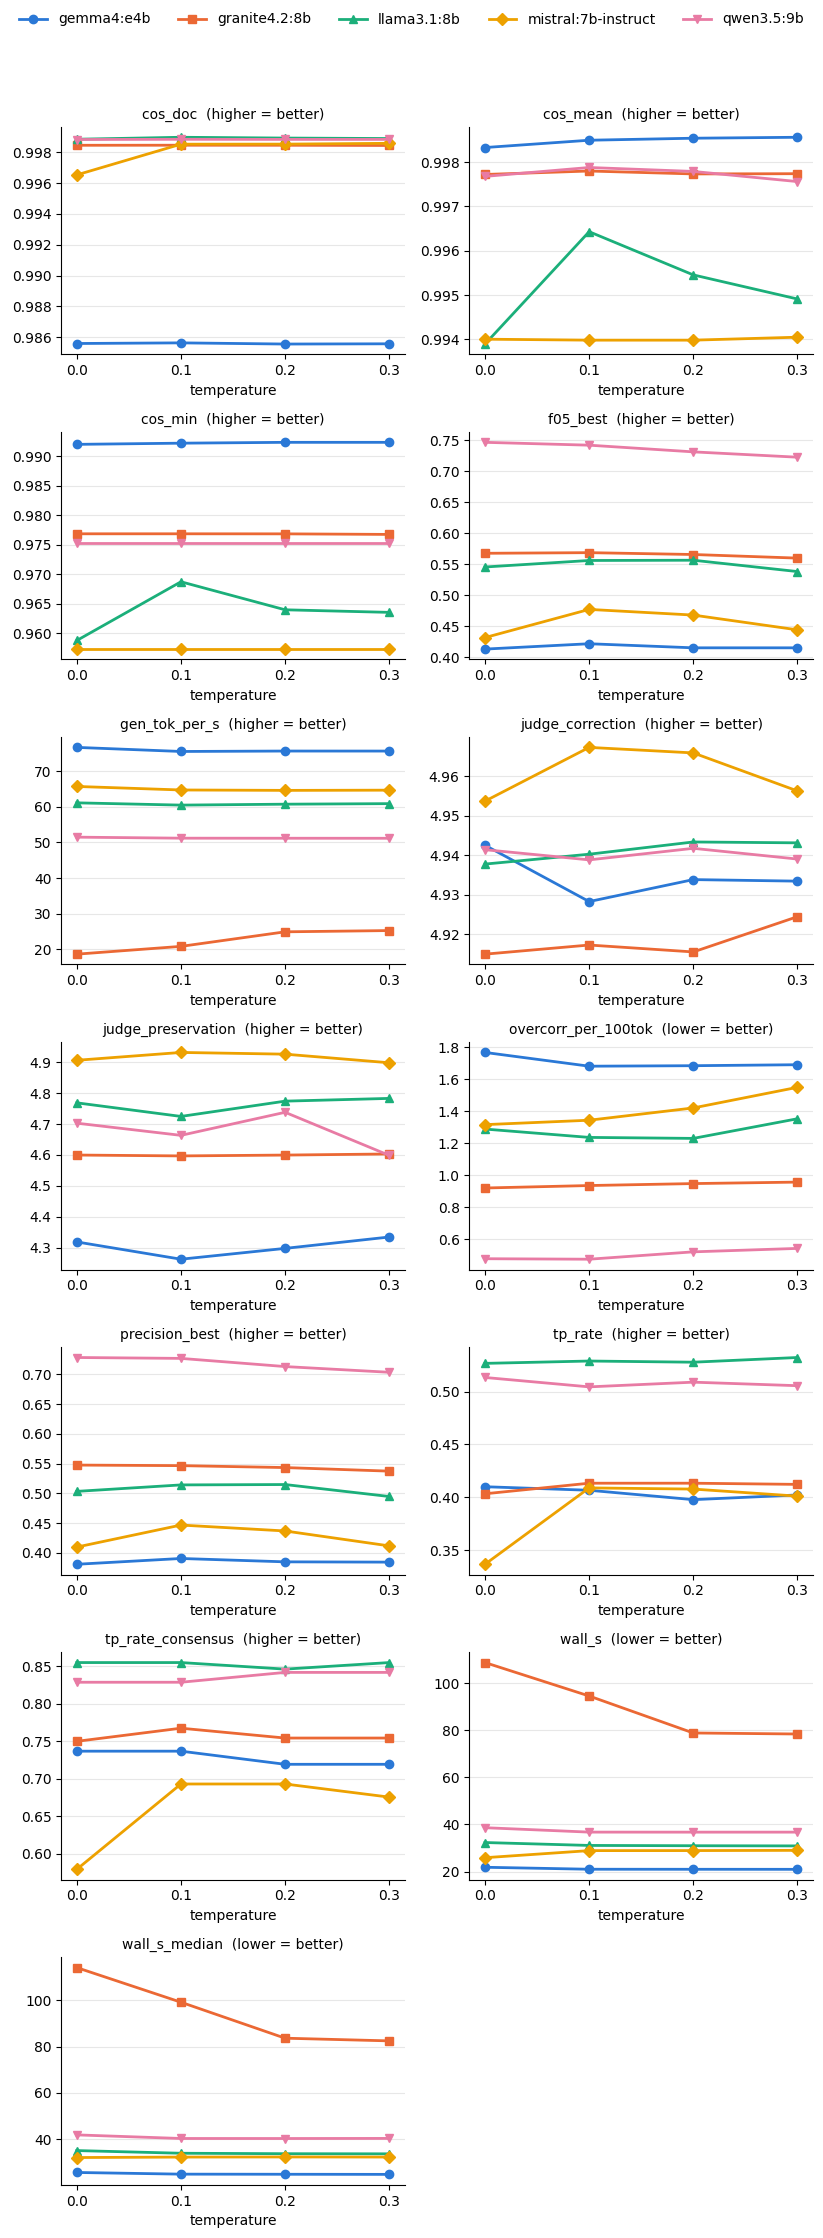

In [31]:
# --------------------------- plots
n_cols = 2
n_rows = -(-len(metrics) // n_cols)  # ceil
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.2 * n_cols, 3.2 * n_rows))
axes = axes.flatten()

for ax, metric in zip(axes, metrics):
    sub = grouped[grouped["metric"] == metric]
    for model in MODELS:
        d = sub[sub["model"] == model]
        if d.empty:
            continue
        ax.plot(
            d["temperature"], d["mean"],
            label=model, linewidth=2, markersize=6, **STYLE[model],
        )
    direction = "lower = better" if metric in LOWER_IS_BETTER else "higher = better"
    ax.set_title(f"{metric}  ({direction})", fontsize=10)
    ax.set_xlabel("temperature")
    ax.set_xticks(sorted(sub["temperature"].unique()))
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

for ax in axes[len(metrics):]:  # hide unused cells
    ax.set_visible(False)

handles = [
    plt.Line2D([], [], linewidth=2, markersize=6, label=m, **STYLE[m]) for m in MODELS
]
fig.legend(handles=handles, loc="upper center", ncol=len(MODELS), frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.savefig("quick_eval.png", dpi=150)
plt.show()

In [ ]:

# ---------------------- rankings
# Per metric: average the mean over all temperatures, plus the best single temperature.
for metric in metrics:
    sub = grouped[grouped["metric"] == metric]
    asc = metric in LOWER_IS_BETTER

    best_rows = (
        sub.sort_values("mean", ascending=asc)
        .groupby("model", as_index=False)
        .first()[["model", "temperature", "mean"]]
        .rename(columns={"temperature": "best_temp", "mean": "best_mean"})
    )
    avg = sub.groupby("model", as_index=False)["mean"].mean().rename(columns={"mean": "avg_mean"})

    ranking = (
        avg.merge(best_rows, on="model")
        .sort_values("avg_mean", ascending=asc)
        .reset_index(drop=True)
    )
    ranking.index += 1  # rank starts at 1
    ranking["best_temp"] = ranking["best_temp"].map("{:.1f}".format)

    arrow = "lower = better" if asc else "higher = better"
    print(f"\n=== {metric} ({arrow}) ===")
    print(ranking.to_string(float_format=lambda x: f"{x:.4f}"))


=== cos_doc (higher = better) ===
                 model  avg_mean best_temp  best_mean
1          llama3.1:8b    0.9989       0.1     0.9990
2           qwen3.5:9b    0.9988       0.1     0.9988
3        granite4.2:8b    0.9984       0.1     0.9985
4  mistral:7b-instruct    0.9980       0.3     0.9986
5           gemma4:e4b    0.9856       0.1     0.9856

=== cos_mean (higher = better) ===
                 model  avg_mean best_temp  best_mean
1           gemma4:e4b    0.9985       0.3     0.9986
2        granite4.2:8b    0.9977       0.1     0.9978
3           qwen3.5:9b    0.9977       0.1     0.9979
4          llama3.1:8b    0.9952       0.1     0.9964
5  mistral:7b-instruct    0.9940       0.3     0.9940

=== cos_min (higher = better) ===
                 model  avg_mean best_temp  best_mean
1           gemma4:e4b    0.9922       0.3     0.9923
2        granite4.2:8b    0.9768       0.0     0.9768
3           qwen3.5:9b    0.9754       0.0     0.9754
4          llama3.1:8b    0.96

# Fiction vs Fiction NoRag

In [32]:
fiction = Path("../../data/eval/results/grammar/fiction")
fiction_norag = Path("../../data/eval/results/grammar/fiction-norag")

embedding_path = fiction / "embedding_refs.csv"
summary_l_path = fiction / "summary_long.csv"
summary_l_path_norag = fiction_norag / "summary_long.csv"

In [33]:
# Metrics where a LOWER mean is better. Everything else: higher is better.
LOWER_IS_BETTER = {"overcorr_per_100tok", "wall_s", "wall_s_median"}

# Fixed colour + marker per model (colourblind-checked categorical palette, fixed order).
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
MARKERS = ["o", "s", "^", "D", "v"]

In [ ]:
# ---------------------------------------------------------------- load + group
def load_grouped(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path)
    df["temperature"] = df["setting_id"].str.lstrip("t").astype(float)
    return (
        df.groupby(["metric", "temperature", "model"], as_index=False)["mean"]
        .mean()
        .sort_values(["metric", "model", "temperature"])
    )


conditions = {
    "RAG": load_grouped(summary_l_path),
    "No RAG": load_grouped(summary_l_path_norag),
}

# Models + metrics across BOTH runs, so colours match left and right.
all_data = pd.concat(conditions.values())
MODELS = sorted(all_data["model"].unique())  # swap for an explicit list once all 5 are in
metrics = sorted(all_data["metric"].unique())

STYLE = {
    m: {"color": PALETTE[i % len(PALETTE)], "marker": MARKERS[i % len(MARKERS)]}
    for i, m in enumerate(MODELS)
}

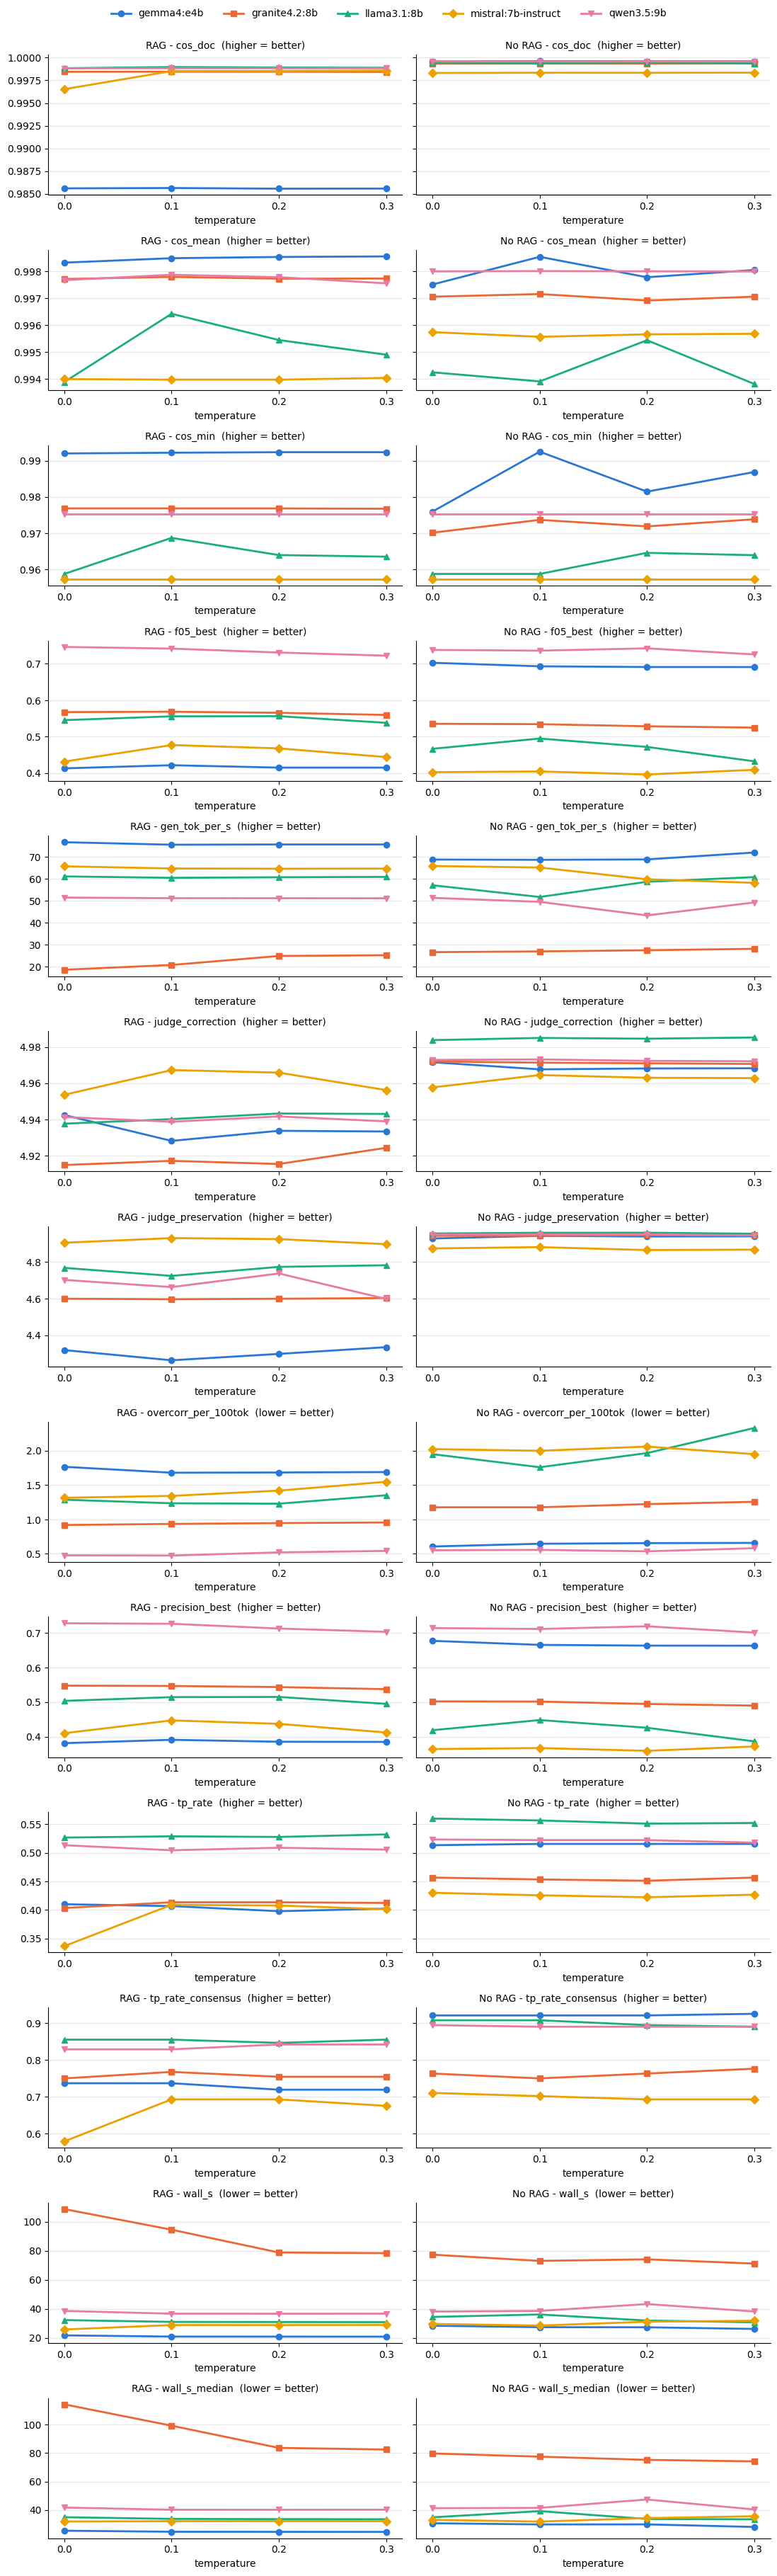

In [36]:

# --------------------------- plots
# One row per metric, left = RAG, right = No RAG. Y-axis shared per row
# so the two sides are directly comparable.
fig, axes = plt.subplots(
    len(metrics), 2,
    figsize=(11, 2.8 * len(metrics)),
    sharey="row",
    squeeze=False,
)

for row, metric in enumerate(metrics):
    direction = "lower = better" if metric in LOWER_IS_BETTER else "higher = better"
    for col, (cond_name, grouped) in enumerate(conditions.items()):
        ax = axes[row, col]
        sub = grouped[grouped["metric"] == metric]
        for model in MODELS:
            d = sub[sub["model"] == model]
            if d.empty:
                continue
            ax.plot(d["temperature"], d["mean"], linewidth=2, markersize=6, **STYLE[model])

        ax.set_title(f"{cond_name} - {metric}  ({direction})", fontsize=10)
        ax.set_xlabel("temperature")
        if not sub.empty:
            ax.set_xticks(sorted(sub["temperature"].unique()))
        ax.grid(axis="y", alpha=0.3)
        ax.spines[["top", "right"]].set_visible(False)

handles = [
    plt.Line2D([], [], linewidth=2, markersize=6, label=m, **STYLE[m]) for m in MODELS
]
fig.legend(handles=handles, loc="upper center", ncol=len(MODELS), frameon=False)
fig.tight_layout(rect=(0, 0, 1, 1 - 0.4 / (2.8 * len(metrics))))
fig.savefig("quick_eval_rag_vs_norag.png", dpi=150)
plt.show()


In [37]:

# ---------------------------------------------------------------- rankings
def ranking(grouped: pd.DataFrame, metric: str) -> pd.DataFrame:
    """Rank models by mean averaged over temperatures, plus best single temperature."""
    sub = grouped[grouped["metric"] == metric]
    asc = metric in LOWER_IS_BETTER
    best = (
        sub.sort_values("mean", ascending=asc)
        .groupby("model", as_index=False)
        .first()[["model", "temperature", "mean"]]
        .rename(columns={"temperature": "best_temp", "mean": "best_mean"})
    )
    avg = sub.groupby("model", as_index=False)["mean"].mean().rename(columns={"mean": "avg_mean"})
    out = avg.merge(best, on="model").sort_values("avg_mean", ascending=asc).reset_index(drop=True)
    out.index += 1
    out["best_temp"] = out["best_temp"].map("{:.1f}".format)
    return out


fmt = lambda x: f"{x:.4f}"  # noqa: E731
for metric in metrics:
    direction = "lower = better" if metric in LOWER_IS_BETTER else "higher = better"
    print(f"\n=== {metric} ({direction}) ===")
    for cond_name, grouped in conditions.items():
        print(f"--- {cond_name}")
        print(ranking(grouped, metric).to_string(float_format=fmt))


=== cos_doc (higher = better) ===
--- RAG
                 model  avg_mean best_temp  best_mean
1          llama3.1:8b    0.9989       0.1     0.9990
2           qwen3.5:9b    0.9988       0.1     0.9988
3        granite4.2:8b    0.9984       0.1     0.9985
4  mistral:7b-instruct    0.9980       0.3     0.9986
5           gemma4:e4b    0.9856       0.1     0.9856
--- No RAG
                 model  avg_mean best_temp  best_mean
1           gemma4:e4b    0.9996       0.1     0.9996
2           qwen3.5:9b    0.9996       0.0     0.9996
3          llama3.1:8b    0.9994       0.2     0.9994
4        granite4.2:8b    0.9994       0.3     0.9994
5  mistral:7b-instruct    0.9983       0.3     0.9983

=== cos_mean (higher = better) ===
--- RAG
                 model  avg_mean best_temp  best_mean
1           gemma4:e4b    0.9985       0.3     0.9986
2        granite4.2:8b    0.9977       0.1     0.9978
3           qwen3.5:9b    0.9977       0.1     0.9979
4          llama3.1:8b    0.9952      